there are three datasets where we consider the co-rotation of the prisms onsky.
1. from 2025A
2. from 2026A, March/April (engineering time)
3. from 2026A, Remote (miles' time)

these datasets were all taken with the telescope at different zenith angles, but that shouldn't affect the co-rotation angle where the speckles were pointed correctly. the question is: is the axis the same for all three?

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
import cv2
from astropy.io import fits
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [6]:
#2025A
cube_25A = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov20th_onsky_newaxis/orientations.fits')[0]
#2026A engineering
#cube_26A = read_field('')
#2026A non-engineering
#going to leave this one out for now

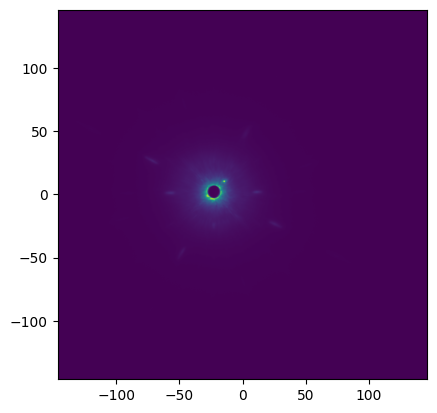

In [7]:
imshow_field(cube_25A[0])

In [8]:
def radial_stretch_from_point(img, stretch_factor, center):
    h, w = img.shape[:2]
    cx, cy = center

    # pixel grid
    y, x = np.indices((h, w), dtype=np.float32)

    # shift relative to chosen center
    dx = x - cx
    dy = y - cy

    # scale vectors
    scale = 1 / stretch_factor

    map_x = (cx + dx * scale).astype(np.float32)
    map_y = (cy + dy * scale).astype(np.float32)
    
    stretched = cv2.remap(
        img,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return stretched

In [9]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 0
grating_freq = 15

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,snr_threshold=2.3,speckle_window=40) 

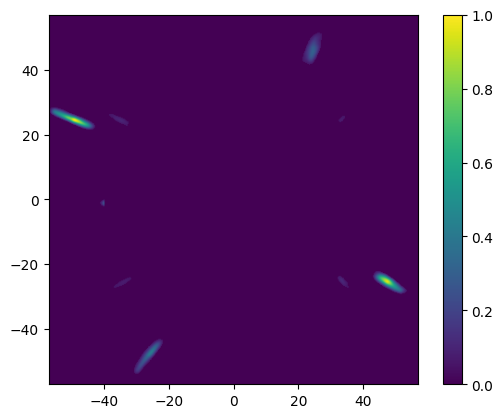

In [36]:
field = cube_25A[14]

dim = np.sqrt(field.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
img = Field(field.ravel(),pgrid)

img = img - np.median(field)
img = ADC.crop_image(img,mask_diam=0,extent=512) #COI method
hp = ADC.hpf(img,10)
hp = hp - ADC.hpf(hp,1)
img = ADC.crop_image(hp,extent=400,mask_diam=80)
img = img / img.max()
img[img < 0.05] = 0
imshow_field(img)
plt.colorbar()

(64, 64)
(np.int64(41), np.int64(33))


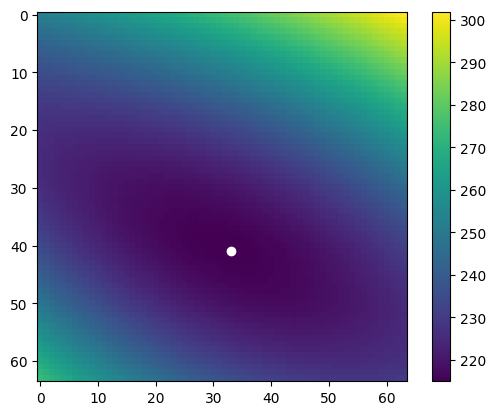

In [28]:
search_size = 64

Z = []
psf = np.array(img.shaped)
center = psf.shape[0]/2

y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

Z = np.array(Z)
Z = np.reshape(Z,y.shape)
Z = np.flip(Z.T,axis=0)
print(Z.shape)
a = np.unravel_index(Z.argmin(),y.shape)
print(a)
plt.imshow(Z)
plt.colorbar()
plt.scatter(a[1],a[0],color='white')

In [31]:
rel_x = np.zeros((15))
rel_y = np.zeros((15))

Z_cube = []
rel_rad_centers = []
dim = np.sqrt(field.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)

search_size = 64

for i, field in enumerate(cube_25A):
    print(f'step {i}')
    img = Field(field.ravel(),pgrid)

    img = img - np.median(field)
    img = ADC.crop_image(img,mask_diam=0,extent=512) #COI method
    hp = ADC.hpf(img,10)
    hp = hp - ADC.hpf(hp,1)
    img = ADC.crop_image(hp,extent=400,mask_diam=80)
    img = img / img.max()
    img[img < 0.05] = 0

    Z = []
    psf = np.array(img.shaped)
    center = psf.shape[0]/2

    y, x = np.meshgrid(
        np.arange(center - search_size/2, center + search_size/2),
        np.arange(center - search_size/2, center + search_size/2),
        indexing="ij"
    )
    indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

    for index in indices:
        psf_stretched = radial_stretch_from_point(psf,1.05,center=index)
        mse = np.sum((psf - psf_stretched)**2)
        Z.append(mse)

    Z = np.array(Z)
    Z = np.reshape(Z,y.shape)
    Z = np.flip(Z.T,axis=0)
    a = np.unravel_index(Z.argmin(),y.shape)

    rel_rad_centers.append(a)
    Z_cube.append(Z)

step 0
step 1
step 2
step 3
step 4
step 5
step 6
step 7
step 8
step 9
step 10
step 11
step 12
step 13
step 14


In [32]:
rel_rad_centers = np.array(rel_rad_centers)
rel_x = rel_rad_centers[:,1]
rel_y = rel_rad_centers[:,0]

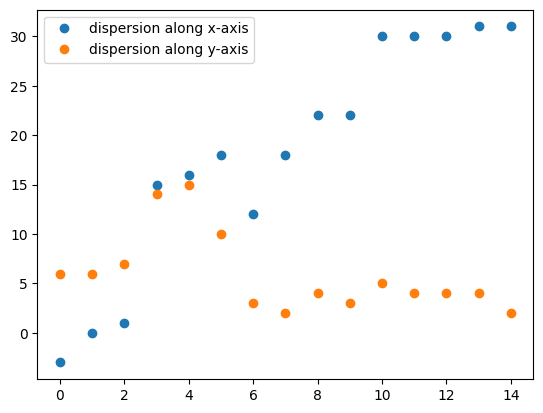

In [35]:
plt.plot(rel_x-search_size/2,'o',label='dispersion along x-axis')
plt.plot(rel_y-search_size/2,'o',label='dispersion along y-axis')
plt.legend()

the orientations that we swept it through were (0,15), and we never checked the other direction to see what was going on. Given the negative sign that was added when we went to NASW, I don't think that this data can be compared to the other data that we have.